In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import pypesto
from pypesto.result import OptimizerResult
import pypesto.profile as profile
from cmfa.opti_functions import ordered_ilr_func, profile_likelihood

import sys
sys.path.insert(0, "../scripts")
import toy_network
import tca_cycle

import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

from jax import config

config.update("jax_enable_x64", True)

import scipy.stats as stats
import optimistix

SEED = 1234
key = jax.random.key(seed=SEED)
key_toy, key = jax.random.split(key)
key_tca, key = jax.random.split(key)
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

combined = "#8CAA8D"
def fisher_interval(log_flux_est, flux_sd):
    mu = log_flux_est
    sigma = flux_sd
    x_start = (mu - 2.4 * sigma)
    x_end = (mu + 2.4 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw / np.max(y_raw)

    return np.exp(x_axis), y_scaled

In [2]:
# Toy network
true_mid_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
simulated_mid_toy = jnp.load(RESULTS_DIR_TOY / "id_simulated_reference.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)


sd_trad_toy = np.std(simulated_mid_toy, axis=0)
sd_ilr_toy = np.std(ordered_ilr_func(simulated_mid_toy), axis=0)

weights_trad_toy = 1/sd_trad_toy
weights_ilr_toy = 1/sd_ilr_toy

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
init_guess_toy = jnp.array([100.0, 50.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_toy = optimistix.minimise(
    toy_network.loss_trad,
    y0=jnp.log(init_guess_toy),
    args=(true_mid_toy, weights_trad_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_toy = optimistix.minimise(
    toy_network.loss_ilr,
    y0=jnp.log(init_guess_toy),
    args=(true_mid_toy, weights_ilr_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

lb_toy=[-6] * 2, 
ub_toy=[6] * 2,  
x_names_toy=['v3', 'v5']

result_trad_toy, ci_trad_profile_toy = profile_likelihood(toy_network.loss_trad, true_mid_toy, sd_trad_toy, np.exp(opt_result_trad_toy.value), opt_result_trad_toy.state.f_info.f, x_names_toy, lb_toy, ub_toy)
result_ilr_toy, ci_ilr_profile_toy = profile_likelihood(toy_network.loss_ilr, true_mid_toy, sd_ilr_toy, np.exp(opt_result_ilr_toy.value), opt_result_ilr_toy.state.f_info.f, x_names_toy, lb_toy, ub_toy)

est_trad_toy = estimated_fluxes_toy["trad"][:, [4, 5]]
est_ilr_toy = estimated_fluxes_toy["ilr"][:, [4, 5]]

inv_hessian_trad_toy = opt_result_trad_toy.state.f_info.hessian_inv.pytree
standard_errors_trad_toy = jnp.sqrt(jnp.diag(inv_hessian_trad_toy))

inv_hessian_ilr_toy = opt_result_ilr_toy.state.f_info.hessian_inv.pytree
standard_errors_ilr_toy = jnp.sqrt(jnp.diag(inv_hessian_ilr_toy))


100%|██████████| 4/4 [00:13<00:00,  3.31s/it]


In [3]:
# tca cycle
true_mid_tca = np.load(RESULTS_DIR_TCA / "true_composition.npy", allow_pickle=True).item()
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True)
simulated_mid_tca = jnp.load(RESULTS_DIR_TCA / "id_simulated_reference.npy", allow_pickle=True).item()

with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

sd_trad_tca = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid_tca)
sd_ilr_tca = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid_tca)

weights_trad_tca = jax.tree.map(lambda s: 1/s, sd_trad_tca)
weights_ilr_tca = jax.tree.map(lambda s: 1/s, sd_ilr_tca)

init_guess_tca = np.array([0.2, 0.2, 0.2])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_tca = optimistix.minimise(
    tca_cycle.loss_trad,
    y0=jnp.log(init_guess_tca),
    args=(true_mid_tca, weights_trad_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_tca = optimistix.minimise(
    tca_cycle.loss_ilr,
    y0=jnp.log(init_guess_tca),
    args=(true_mid_tca, weights_ilr_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

lb_tca = [-5] * 3, 
ub_tca = [5] * 3,  
x_names_tca = ['v8', 'v2', "v9"]

result_trad_tca, ci_tca_profile_trad = profile_likelihood(tca_cycle.loss_trad, true_mid_tca, sd_trad_tca, np.exp(opt_result_trad_tca.value), opt_result_trad_tca.state.f_info.f, x_names_tca, lb_tca, ub_tca, use_jax_weights=True)
result_ilr_tca, ci_tca_profile_ilr = profile_likelihood(tca_cycle.loss_ilr, true_mid_tca, sd_ilr_tca, np.exp(opt_result_ilr_tca.value), opt_result_ilr_tca.state.f_info.f, x_names_tca, lb_tca, ub_tca, use_jax_weights=True)

est_trad_tca = estimated_fluxes_tca["trad"]
est_ilr_tca = estimated_fluxes_tca["ilr"]

inv_hessian_trad_tca = opt_result_trad_tca.state.f_info.hessian_inv.pytree
standard_errors_trad_tca = jnp.sqrt(jnp.diag(inv_hessian_trad_tca))

inv_hessian_ilr_tca = opt_result_ilr_tca.state.f_info.hessian_inv.pytree
standard_errors_ilr_tca = jnp.sqrt(jnp.diag(inv_hessian_ilr_tca))

100%|██████████| 6/6 [04:18<00:00, 43.10s/it] 


findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not found.
findfont: Font family 'Roboto' not

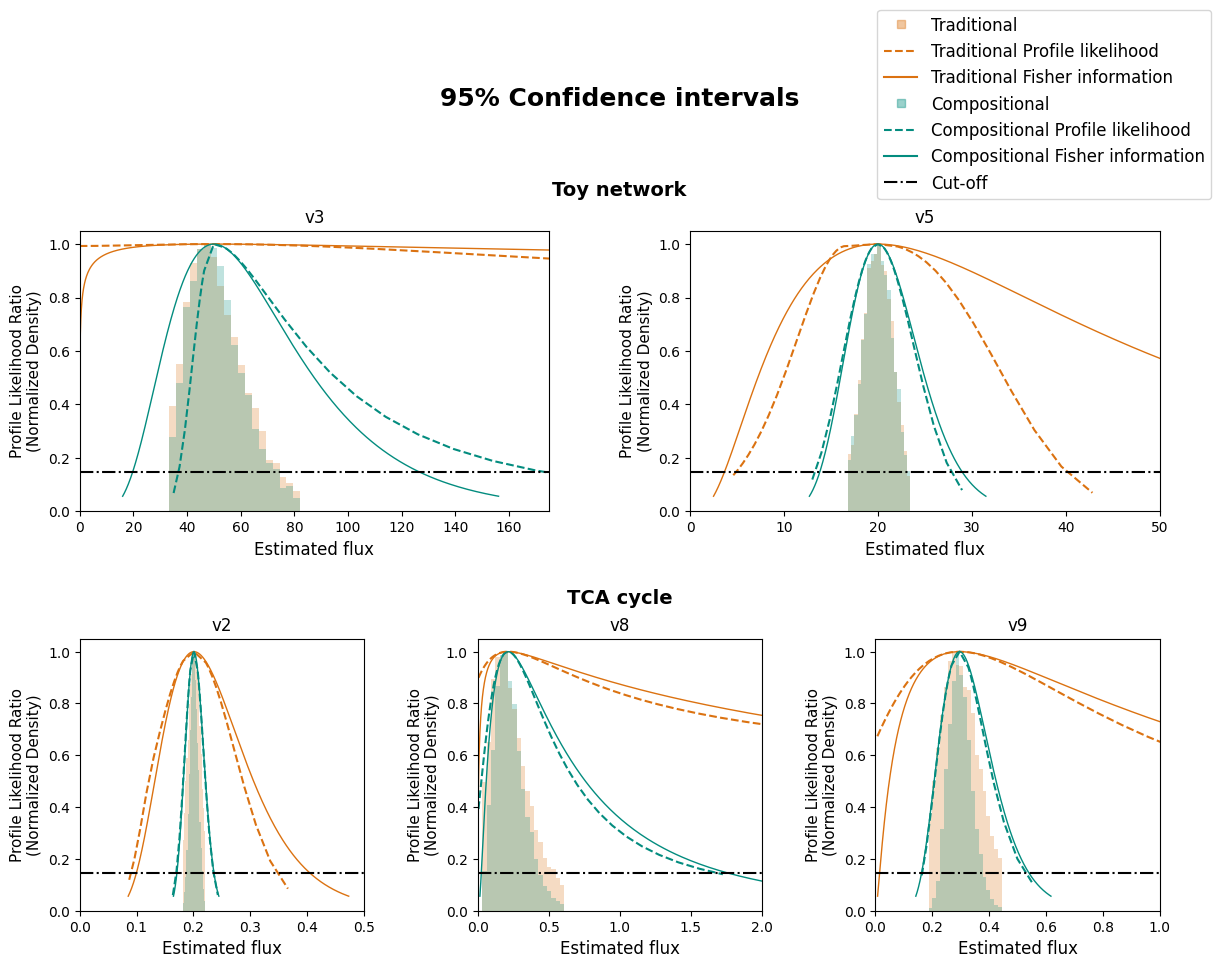

In [36]:
# --- Figure & Layout Setup ---
f = plt.figure(figsize=(12, 8.5)) 

# Top Row (Toy Network)
gs1 = gridspec.GridSpec(1, 2, left=0.05, right=0.95, top=0.88, bottom=0.55, wspace=0.3)
ax1, ax2 = plt.subplot(gs1[0]), plt.subplot(gs1[1])
f.add_subplot(gs1[:, :], frameon=False).set_title("Toy network", fontsize=14, fontweight='bold', pad=25)
plt.axis('off')

# Bottom Row (TCA Cycle)
gs2 = gridspec.GridSpec(1, 3, left=0.05, right=0.95, top=0.40, bottom=0.08, wspace=0.4)
ax3, ax4, ax5 = plt.subplot(gs2[0]), plt.subplot(gs2[1]), plt.subplot(gs2[2])
f.add_subplot(gs2[:, :], frameon=False).set_title("TCA cycle", fontsize=14, fontweight='bold', pad=25)
plt.axis('off')

axes = [ax1, ax2, ax3, ax4, ax5]

# --- Unified Subplot Configuration ---
# Bundles the variations across datasets to eliminate the if/else structural branch
configs = [
    # Toy Network Subplots
    {"res_t": result_trad_toy, "res_i": result_ilr_toy, "idx": 0, "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0], "title": "v3", "xlim": (0, 175)},
    {"res_t": result_trad_toy, "res_i": result_ilr_toy, "idx": 1, "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 1], "est_i": est_ilr_toy[:, 1], "title": "v5", "xlim": (0, 50)},
    # TCA Cycle Subplots (Maps exactly to your index arrays/titles layout)
    {"res_t": result_trad_tca, "res_i": result_ilr_tca, "idx": 1, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 1], "est_i": est_ilr_tca[:, 1], "title": "v2", "xlim": (0, 0.5)},
    {"res_t": result_trad_tca, "res_i": result_ilr_tca, "idx": 0, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 0], "est_i": est_ilr_tca[:, 0], "title": "v8", "xlim": (0, 2)},
    {"res_t": result_trad_tca, "res_i": result_ilr_tca, "idx": 2, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 2], "est_i": est_ilr_tca[:, 2], "title": "v9", "xlim": (0, 1)},
]

# --- Execution Loop ---
for ax, cfg in zip(axes, configs):
    idx, rt, ri = cfg["idx"], cfg["res_t"], cfg["res_i"]
    et, ei = cfg["est_t"].flatten(), cfg["est_i"].flatten()

    # 1. Profile Likelihood Paths
    ax.plot(rt.profile_result.get_profiler_result(idx)["x_path"][idx], rt.profile_result.get_profiler_result(idx)["ratio_path"], color=TRAD, linestyle="--")
    ax.plot(ri.profile_result.get_profiler_result(idx)["x_path"][idx], ri.profile_result.get_profiler_result(idx)["ratio_path"], color=ILR, linestyle="--")
    
    # 2. Fisher Information Intervals
    ax.plot(*fisher_interval(cfg["opt_t"].value[idx], cfg["se_t"][idx]), color=TRAD, lw=1)
    ax.plot(*fisher_interval(cfg["opt_i"].value[idx], cfg["se_i"][idx]), color=ILR, lw=1)
    
    # 3. Peak-Normalized Histograms
    bins = np.linspace(np.quantile(np.concatenate([et, ei]), 0.025), np.quantile(np.concatenate([et, ei]), 0.975), 20)
    ax.hist(et, bins=bins, weights=np.ones_like(et) / np.max(np.histogram(et, bins=bins)[0]), color=TRAD, alpha=0.25)
    ax.hist(ei, bins=bins, weights=np.ones_like(ei) / np.max(np.histogram(ei, bins=bins)[0]), color=ILR, alpha=0.25)
    
    # 4. Global Subplot Formatting
    ax.axhline(0.1465, color="black", linestyle="-.")
    ax.set_title(cfg["title"])
    ax.set_xlim(cfg["xlim"])
    ax.set_xlabel("Estimated flux", fontsize=12)
    ax.set_ylabel("Profile Likelihood Ratio\n(Normalized Density)", fontsize=11)

# --- Legend & Figure Output ---
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="s", linestyle="", markersize=6, alpha=0.4),
    Line2D([0], [0], color=TRAD, linestyle="--", markersize=6),
    Line2D([0], [0], color=TRAD, linestyle="-", markersize=6), 
    Line2D([0], [0], color=ILR, marker="s", linestyle="", markersize=6, alpha=0.4),
    Line2D([0], [0], color=ILR, linestyle="--", markersize=6),
    Line2D([0], [0], color=ILR, linestyle="-", markersize=6),
    Line2D([0], [0], color="black", linestyle="-.", markersize=6),
]

f.legend(
    custom_marker, 
    ["Traditional", "Traditional Profile likelihood", "Traditional Fisher information", 
     "Compositional", "Compositional Profile likelihood", "Compositional Fisher information", "Cut-off"], 
    fontsize=12, loc="upper right", bbox_to_anchor=(1, 1.15)
)

f.suptitle("95% Confidence intervals", fontsize=18, fontweight='bold', y=1.05)
plt.savefig(PLOT_DIR / 'CI.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()